# Introduction

You are welcome to fork this notebook, improve it, and try to get a better score on the competition leaderboard.

Import the packages that will be used:

In [93]:
import os
import kagglehub

import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score

Download the competition dataset:

In [94]:
path = kagglehub.competition_download('flower-species-2026')

path

'C:\\Users\\ricky\\.cache\\kagglehub\\competitions\\flower-species-2026'

# Training data

Read the training data from a CSV file, using the *id* column as index:

In [95]:
df = pd.read_csv(os.path.join(path, 'train.csv'), index_col='id')

df

,sepal_length,sepal_width,petal_length,petal_width,species
id,,,,,
1,6.4,3.2,4.6,1.5,versicolor
2,5.6,3.6,1.4,0.3,setosa
3,7.0,2.6,4.9,1.5,versicolor
4,6.0,4.4,2.0,0.5,setosa
5,6.0,4.2,1.8,0.3,setosa
...,...,...,...,...,...
116,5.4,3.4,1.6,0.2,setosa
117,6.5,3.1,5.7,2.2,virginica
118,7.7,3.6,6.4,2.6,virginica


# Feature correlations

Compute the correlations between features:

In [96]:
feature_columns = df.columns[:4]

corr = df[feature_columns].corr()

corr

,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000000,-0.124704,0.861168,0.802657
sepal_width,-0.124704,1.000000,-0.446646,-0.382983
petal_length,0.861168,-0.446646,1.000000,0.960686
petal_width,0.802657,-0.382983,0.960686,1.000000


Plot a heatmap to visualize the feature correlations:

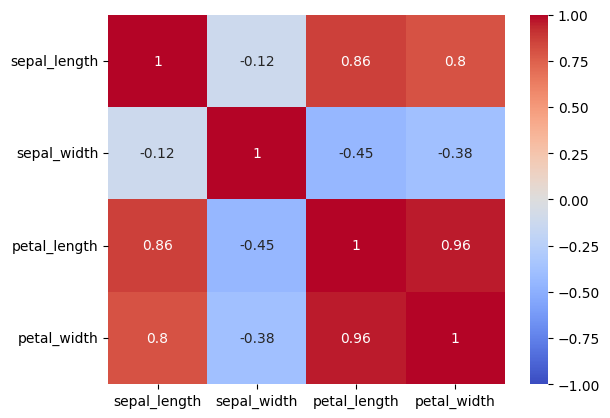

In [97]:
ax = sns.heatmap(data=corr, vmin=-1, vmax=1, annot=True, cmap='coolwarm')

ax.tick_params(axis='y', rotation=0)

Since some features are highly correlated, they are somewhat redundant, so we might not need to use them all.

Therefore, we will try reducing the dimensionality of the dataset into a smaller set of uncorrelated components.

# Data scaling

Prepare a standard scaler to rescale (standardize) the features:

In [98]:
scaler = StandardScaler()

scaler

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


Fit the scaler to the training set:

In [99]:
scaler.fit(df[feature_columns])

StandardScaler()

Use the scaler to transform each feature to zero mean and unit variance:

In [100]:
df[feature_columns] = scaler.transform(df[feature_columns])

df

,sepal_length,sepal_width,petal_length,petal_width,species
id,,,,,
1,-0.121084,-0.541087,0.195297,0.117183,versicolor
2,-1.043631,0.294031,-1.482421,-1.312845,setosa
3,0.570826,-1.793765,0.352583,0.117183,versicolor
4,-0.582358,1.964269,-1.167849,-1.074507,setosa
5,-0.582358,1.546709,-1.272707,-1.312845,setosa
...,...,...,...,...,...
116,-1.274267,-0.123528,-1.377564,-1.432014,setosa
117,-0.005766,-0.749867,0.772012,0.951365,virginica
118,1.378054,0.294031,1.139013,1.428041,virginica


# Dimensionality reduction

Prepare a dimensionality reduction based on PCA (Principal Component Analysis):

In [101]:
pca = PCA(n_components=3, random_state=0)

pca

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",3
,"random_state random_state: int, RandomState instance or None, default=NoneUsed when the 'arpack' or 'randomized' solvers are used. Pass an intfor reproducible results across multiple function calls.See :term:`Glossary <random_state>`... versionadded:: 0.18.0",0
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ens

Fit the PCA to the training data:

In [102]:
pca.fit(df[feature_columns])

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",3
,"random_state random_state: int, RandomState instance or None, default=NoneUsed when the 'arpack' or 'randomized' solvers are used. Pass an intfor reproducible results across multiple function calls.See :term:`Glossary <random_state>`... versionadded:: 0.18.0",0
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ens

The two components (let's call them *x1* and *x2*) seem to be enough to explain most of the variance in the data:

In [103]:
evr = pca.explained_variance_ratio_

print('Explained variance (x1):    {:.1f}%'.format(evr[0] * 100))
print('Explained variance (x2):    {:.1f}%'.format(evr[1] * 100))
print('Explained variance (x3):    {:.1f}%'.format(evr[2] * 100))
print('Explained variance (total): {:.1f}%'.format(evr.sum() * 100))

Explained variance (x1):    72.9%
Explained variance (x2):    22.6%
Explained variance (x3):    4.0%
Explained variance (total): 99.5%


Use the PCA to transform the features to a lower dimensionality:

In [104]:
df[['x1', 'x2', 'x3']] = pca.transform(df[feature_columns])

df

,sepal_length,sepal_width,petal_length,petal_width,species,x1,x2,x3
id,,,,,,,,
1,-0.121084,-0.541087,0.195297,0.117183,versicolor,0.269413,-0.530169,-0.048617
2,-1.043631,0.294031,-1.482421,-1.312845,setosa,-2.221567,-0.272252,0.225100
3,0.570826,-1.793765,0.352583,0.117183,versicolor,1.070425,-1.397444,0.747575
4,-0.582358,1.964269,-1.167849,-1.074507,setosa,-2.137288,1.463358,-0.075282
5,-0.582358,1.546709,-1.272707,-1.312845,setosa,-2.214873,1.062604,0.199288
...,...,...,...,...,...,...,...,...
116,-1.274267,-0.123528,-1.377564,-1.432014,setosa,-2.229181,-0.751084,0.229163
117,-0.005766,-0.749867,0.772012,0.951365,virginica,1.192697,-0.604423,-0.524364
118,1.378054,0.294031,1.139013,1.428041,virginica,2.093962,0.941737,-0.162334


Plot the data points in the new feature space:

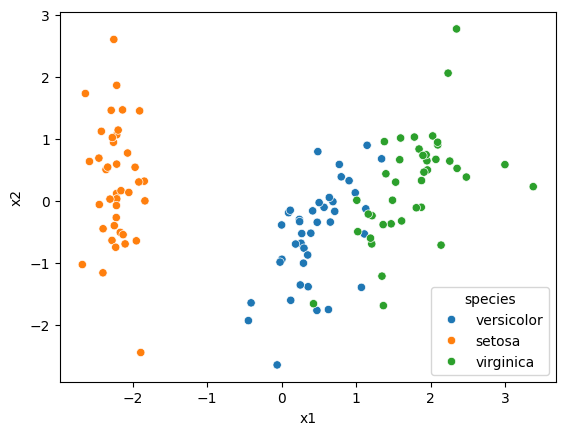

In [105]:
sns.scatterplot(data=df, x='x1', y='x2', hue='species');

The classes are almost separable; there is some overlap between *virginica* and *versicolor*.

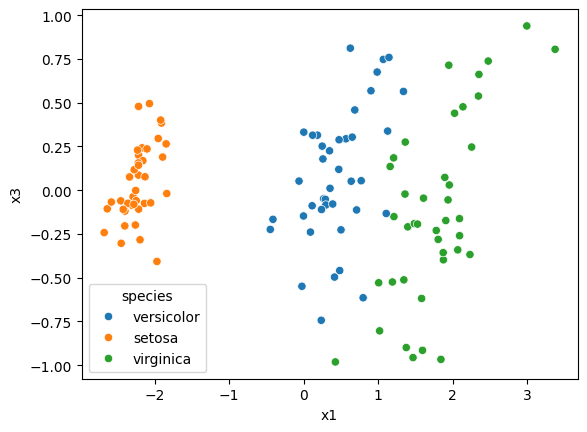

In [106]:
sns.scatterplot(data=df, x='x1', y='x3', hue='species');

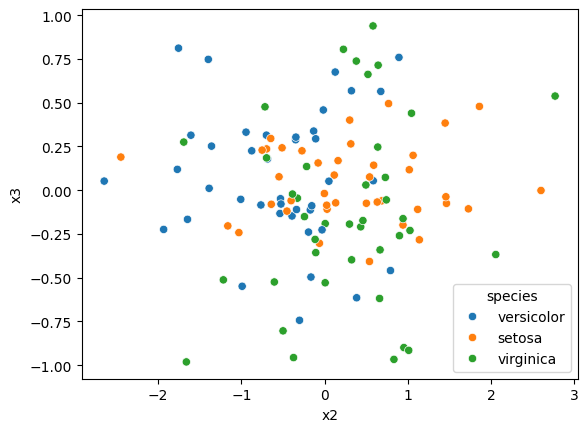

In [107]:
sns.scatterplot(data=df, x='x2', y='x3', hue='species');

# Data splitting

Split the training data into a training set and a validation set:

In [108]:
df_train, df_valid = train_test_split(df,
                                      test_size=0.2,
                                      random_state=0,
                                      stratify=df['species'])

print(df_train.shape, df_valid.shape)

(96, 8) (24, 8)


# Cluster analysis

Prepare a clustering algorithm (*k*-means) to be used on the new feature space:

In [109]:
kmeans = KMeans(n_clusters=3, random_state=0)

kmeans

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


Fit the clustering algorithm (*k*-means) to the training set:

In [110]:
kmeans.fit(df_train[['x1', 'x2', 'x3']])

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 3)","[[

We know have three clusters centered on these points:

In [111]:
centroids = pd.DataFrame(kmeans.cluster_centers_, columns=['x1', 'x2', 'x3'])

centroids

,x1,x2,x3
0,1.776987,0.508474,0.047797
1,-2.234107,0.393235,0.007499
2,0.358434,-0.907099,-0.028785


We can plot the data points and the cluster centers in feature space:

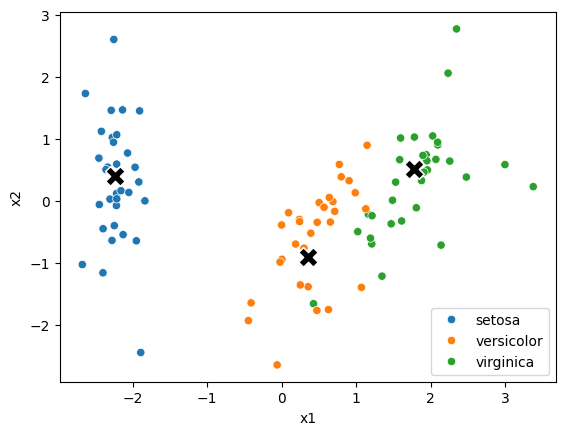

In [112]:
sns.scatterplot(data=df_train, x='x1', y='x2', hue='species')

sns.scatterplot(x=centroids['x1'], y=centroids['x2'], color='black', marker='X', s=200);

If we ever need to project these points back to the original feature space, we can do that with inverse transforms:

In [113]:
centroids = scaler.inverse_transform(pca.inverse_transform(kmeans.cluster_centers_))

pd.DataFrame(centroids, columns=feature_columns)

,sepal_length,sepal_width,petal_length,petal_width
0,7.504316,3.436284,6.207282,2.245343
1,5.645984,3.932034,1.771808,0.362908
2,6.335128,3.016843,4.586583,1.535656


To find out which samples belong to each cluster, we can use the cluster labels:

In [114]:
df_train['cluster'] = kmeans.labels_

df_train

,sepal_length,sepal_width,petal_length,petal_width,species,x1,x2,x3,cluster
id,,,,,,,,,
42,-1.389586,0.294031,-1.220278,-1.312845,setosa,-2.247810,-0.402701,-0.059737,1
89,1.032099,-0.123528,0.352583,0.236352,versicolor,0.904933,0.321897,0.568164,0
103,-1.158949,-1.376206,0.405012,0.713028,virginica,0.427089,-1.661017,-0.981160,2
101,1.724009,0.294031,1.296299,0.832197,virginica,2.027774,1.043428,0.439823,0
91,2.646555,1.755489,1.506014,1.070534,virginica,2.347878,2.768401,0.538061,0
...,...,...,...,...,...,...,...,...,...
111,0.340189,-0.123528,0.509869,0.236352,versicolor,0.639420,0.051312,0.051456,2
22,0.801462,-0.541087,0.509869,0.474690,versicolor,1.129284,-0.131653,0.337948,0
69,-0.121084,1.755489,-1.167849,-1.193676,setosa,-1.907776,1.447523,0.383775,1


From these labels, we can analyze the composition of each cluster:

In [115]:
df_train.groupby('cluster')['species'].value_counts().unstack(fill_value=0)

species,setosa,versicolor,virginica
cluster,,,
0,0,6,27
1,31,0,0
2,1,26,5


Also, we can establish a correspondence between clusters and species, via the majority species (i.e. the mode) for each cluster:

In [116]:
cluster_species = df_train.groupby('cluster')['species'].agg(pd.Series.mode)

cluster_species.to_frame()

,species
cluster,
0,virginica
1,setosa
2,versicolor


# Cluster prediction

For evaluation purposes, predict the cluster for each sample in the validation set:

In [117]:
df_valid['cluster'] = kmeans.predict(df_valid[['x1', 'x2', 'x3']])

df_valid

,sepal_length,sepal_width,petal_length,petal_width,species,x1,x2,x3,cluster
id,,,,,,,,,
107,0.570826,-0.749867,0.667155,0.832197,virginica,1.361996,-0.386209,-0.021986,0
70,1.839327,-0.332308,1.453585,0.832197,virginica,2.354992,0.520287,0.661900,0
65,-0.005766,2.173048,-1.482421,-1.312845,setosa,-2.215714,1.859097,0.478786,1
97,-0.121084,-0.123528,0.247726,-0.001986,versicolor,0.115031,-0.154697,-0.088908,2
7,-0.582358,0.711591,-1.272707,-1.074507,setosa,-1.845246,0.314427,0.264736,1
17,-1.158949,0.085252,-1.272707,-1.432014,setosa,-2.167666,-0.511499,0.242217,1
57,0.686144,-0.541087,1.086585,1.308872,virginica,1.874814,-0.106458,-0.356616,0
100,-0.351721,-1.584986,-0.014418,-0.240324,versicolor,0.121304,-1.606318,0.314430,2
2,-1.043631,0.294031,-1.482421,-1.312845,setosa,-2.221567,-0.272252,0.225100,1


Map each cluster prediction to its corresponding species:

In [118]:
df_valid['prediction'] = df_valid['cluster'].map(cluster_species)

df_valid

,sepal_length,sepal_width,petal_length,petal_width,species,x1,x2,x3,cluster,prediction
id,,,,,,,,,,
107,0.570826,-0.749867,0.667155,0.832197,virginica,1.361996,-0.386209,-0.021986,0,virginica
70,1.839327,-0.332308,1.453585,0.832197,virginica,2.354992,0.520287,0.661900,0,virginica
65,-0.005766,2.173048,-1.482421,-1.312845,setosa,-2.215714,1.859097,0.478786,1,setosa
97,-0.121084,-0.123528,0.247726,-0.001986,versicolor,0.115031,-0.154697,-0.088908,2,versicolor
7,-0.582358,0.711591,-1.272707,-1.074507,setosa,-1.845246,0.314427,0.264736,1,setosa
17,-1.158949,0.085252,-1.272707,-1.432014,setosa,-2.167666,-0.511499,0.242217,1,setosa
57,0.686144,-0.541087,1.086585,1.308872,virginica,1.874814,-0.106458,-0.356616,0,virginica
100,-0.351721,-1.584986,-0.014418,-0.240324,versicolor,0.121304,-1.606318,0.314430,2,versicolor
2,-1.043631,0.294031,-1.482421,-1.312845,setosa,-2.221567,-0.272252,0.225100,1,setosa


Determine which predictions are correct:

In [119]:
df_valid['correct'] = (df_valid['species'] == df_valid['prediction'])

df_valid

,sepal_length,sepal_width,petal_length,petal_width,species,x1,x2,x3,cluster,prediction,correct
id,,,,,,,,,,,
107,0.570826,-0.749867,0.667155,0.832197,virginica,1.361996,-0.386209,-0.021986,0,virginica,True
70,1.839327,-0.332308,1.453585,0.832197,virginica,2.354992,0.520287,0.661900,0,virginica,True
65,-0.005766,2.173048,-1.482421,-1.312845,setosa,-2.215714,1.859097,0.478786,1,setosa,True
97,-0.121084,-0.123528,0.247726,-0.001986,versicolor,0.115031,-0.154697,-0.088908,2,versicolor,True
7,-0.582358,0.711591,-1.272707,-1.074507,setosa,-1.845246,0.314427,0.264736,1,setosa,True
17,-1.158949,0.085252,-1.272707,-1.432014,setosa,-2.167666,-0.511499,0.242217,1,setosa,True
57,0.686144,-0.541087,1.086585,1.308872,virginica,1.874814,-0.106458,-0.356616,0,virginica,True
100,-0.351721,-1.584986,-0.014418,-0.240324,versicolor,0.121304,-1.606318,0.314430,2,versicolor,True
2,-1.043631,0.294031,-1.482421,-1.312845,setosa,-2.221567,-0.272252,0.225100,1,setosa,True


Show a scatter plot of correct vs. incorrect predictions:

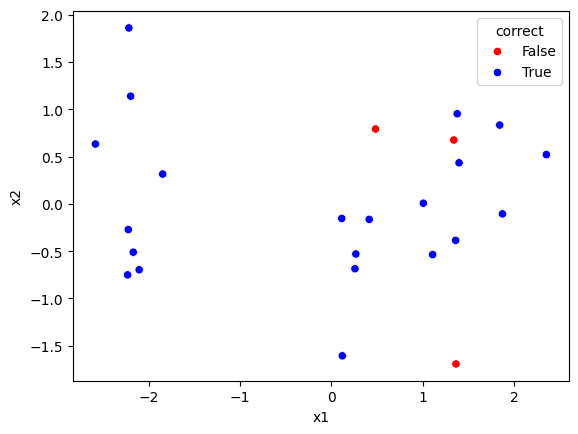

In [120]:
sns.scatterplot(data=df_valid,
                x='x1',
                y='x2',
                hue='correct',
                palette={True: 'blue', False: 'red'});

Plot the confusion matrix of true vs. predicted labels:

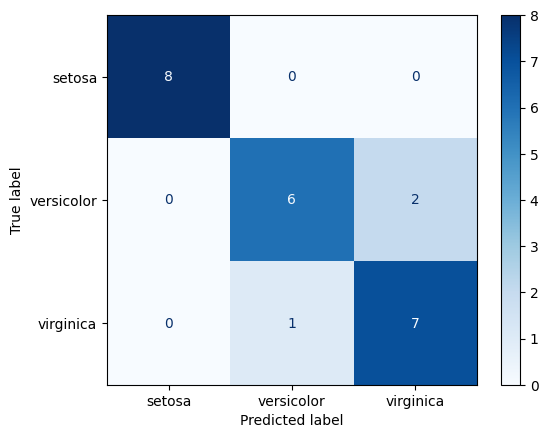

In [121]:
ConfusionMatrixDisplay.from_predictions(df_valid['species'],
                                        df_valid['prediction'],
                                        cmap='Blues');

Show the accuracy on the validation set:

In [122]:
accuracy_score(df_valid['species'], df_valid['prediction'])

0.875

The result should be the same as:

In [123]:
print(df_valid['correct'].sum() / df_valid.shape[0])

0.875


# Test data

Read the test data from a CSV file, using the *id* column as index:

In [124]:
df_test = pd.read_csv(os.path.join(path, 'test.csv'), index_col='id')

df_test

,sepal_length,sepal_width,petal_length,petal_width
id,,,,
121,6.2,2.7,4.3,1.3
122,5.4,3.4,1.6,0.4
123,7.5,3.7,6.4,2.8
124,7.2,3.6,5.7,2.3
125,4.9,3.4,1.5,0.3
126,5.3,3.6,1.5,0.3
127,8.6,3.4,6.8,2.6
128,7.0,2.8,5.5,1.8
129,6.7,3.4,5.4,2.1


Apply the standard scaler to the test data:

In [125]:
df_test[feature_columns] = scaler.transform(df_test[feature_columns])

df_test

,sepal_length,sepal_width,petal_length,petal_width
id,,,,
121,-0.351721,-1.584986,0.038011,-0.121155
122,-1.274267,-0.123528,-1.377564,-1.193676
123,1.147417,0.502811,1.139013,1.666379
124,0.801462,0.294031,0.772012,1.070534
125,-1.850859,-0.123528,-1.429993,-1.312845
126,-1.389586,0.294031,-1.429993,-1.312845
127,2.415919,-0.123528,1.348728,1.428041
128,0.570826,-1.376206,0.667155,0.474690
129,0.224871,-0.123528,0.614726,0.832197


Apply the dimensionality reduction to the test data:

In [126]:
df_test[['x1', 'x2', 'x3']] = pca.transform(df_test[feature_columns])

df_test

,sepal_length,sepal_width,petal_length,petal_width,x1,x2,x3
id,,,,,,,
121,-0.351721,-1.584986,0.038011,-0.121155,0.218914,-1.596968,0.231292
122,-1.274267,-0.123528,-1.377564,-1.193676,-2.094825,-0.735152,0.078022
123,1.147417,0.502811,1.139013,1.666379,2.050563,1.057117,-0.532293
124,0.801462,0.294031,0.772012,1.070534,1.382063,0.679205,-0.294329
125,-1.850859,-0.123528,-1.429993,-1.312845,-2.489776,-0.973449,-0.250515
126,-1.389586,0.294031,-1.429993,-1.312845,-2.369539,-0.408237,-0.029470
127,2.415919,-0.123528,1.348728,1.428041,2.868539,0.977323,0.656706
128,0.570826,-1.376206,0.667155,0.474690,1.336916,-0.983189,0.367168
129,0.224871,-0.123528,0.614726,0.832197,0.976706,0.048120,-0.423866


Predict the cluster for each sample in the test set:

In [127]:
df_test['cluster'] = kmeans.predict(df_test[['x1', 'x2', 'x3']])

df_test

,sepal_length,sepal_width,petal_length,petal_width,x1,x2,x3,cluster
id,,,,,,,,
121,-0.351721,-1.584986,0.038011,-0.121155,0.218914,-1.596968,0.231292,2
122,-1.274267,-0.123528,-1.377564,-1.193676,-2.094825,-0.735152,0.078022,1
123,1.147417,0.502811,1.139013,1.666379,2.050563,1.057117,-0.532293,0
124,0.801462,0.294031,0.772012,1.070534,1.382063,0.679205,-0.294329,0
125,-1.850859,-0.123528,-1.429993,-1.312845,-2.489776,-0.973449,-0.250515,1
126,-1.389586,0.294031,-1.429993,-1.312845,-2.369539,-0.408237,-0.029470,1
127,2.415919,-0.123528,1.348728,1.428041,2.868539,0.977323,0.656706,0
128,0.570826,-1.376206,0.667155,0.474690,1.336916,-0.983189,0.367168,2
129,0.224871,-0.123528,0.614726,0.832197,0.976706,0.048120,-0.423866,0


Map each cluster to its corresponding species:

In [128]:
df_test['species'] = df_test['cluster'].map(cluster_species)

df_test

,sepal_length,sepal_width,petal_length,petal_width,x1,x2,x3,cluster,species
id,,,,,,,,,
121,-0.351721,-1.584986,0.038011,-0.121155,0.218914,-1.596968,0.231292,2,versicolor
122,-1.274267,-0.123528,-1.377564,-1.193676,-2.094825,-0.735152,0.078022,1,setosa
123,1.147417,0.502811,1.139013,1.666379,2.050563,1.057117,-0.532293,0,virginica
124,0.801462,0.294031,0.772012,1.070534,1.382063,0.679205,-0.294329,0,virginica
125,-1.850859,-0.123528,-1.429993,-1.312845,-2.489776,-0.973449,-0.250515,1,setosa
126,-1.389586,0.294031,-1.429993,-1.312845,-2.369539,-0.408237,-0.029470,1,setosa
127,2.415919,-0.123528,1.348728,1.428041,2.868539,0.977323,0.656706,0,virginica
128,0.570826,-1.376206,0.667155,0.474690,1.336916,-0.983189,0.367168,2,versicolor
129,0.224871,-0.123528,0.614726,0.832197,0.976706,0.048120,-0.423866,0,virginica


Prepare a submission:

In [129]:
df_submission = df_test['species'].to_frame()

df_submission

,species
id,
121,versicolor
122,setosa
123,virginica
124,virginica
125,setosa
126,setosa
127,virginica
128,versicolor
129,virginica


Save the submission file:

In [130]:
df_submission.to_csv('submission.csv')

Submit this file to the competition, and check your score on the leaderboard!🍀